# 04 — Model Comparison: Decision Tree and Random Forest

**Week 5:** try Decision Tree and Random Forest, compare test R² (and MdAPE) with the Week 4 baseline, and note each model's strengths and weaknesses.

Same setup as Week 4: 24 leakage-free features, Week 3 preprocessor, target `log(ClosePrice)`, train Jan 2025 – Mar 2026, test Apr 2026. Hyperparameters are chosen on the Jan–Mar 2026 validation months only; April is scored once.

**To beat (Linear Regression):** April MdAPE 8.63%, R² 0.889; validation mean MdAPE 8.75%.

## 1. Setup

In [1]:
import sys, json, time, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

ROOT = next(p for p in [Path("."), Path("..")] if (p / "processed").exists()).resolve()
sys.path.insert(0, str(ROOT / "py"))
import preprocessing as pp
import modeling as mdl

PROC, FIG_DIR = ROOT / "processed", ROOT / "figures" / "04_model_comparison"
RES_DIR, MODEL_DIR = ROOT / "results", ROOT / "models"
for d in (FIG_DIR, RES_DIR, MODEL_DIR): d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#2e9e6a", "#8a8984"
COLORS = {"Linear Regression": GREY, "Decision Tree": ORANGE, "Random Forest": BLUE}
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d0cfca", "grid.color": "#ecebe7",
                                     "axes.titleweight": "bold", "figure.dpi": 110})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)
def fmt_table(df, spec):
    out = df.copy()
    for c, f in spec.items():
        if c in out.columns: out[c] = out[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    return out
METRIC_FMT = {"n": "{:,.0f}", "n_train": "{:,.0f}", "MdAPE": "{:.2f}%", "R2": "{:.4f}", "R2_log": "{:.4f}",
              "MAPE": "{:.2f}%", "MAE": "${:,.0f}", "RMSE": "${:,.0f}", "MedAE": "${:,.0f}",
              "within_5pct": "{:.1f}%", "within_10pct": "{:.1f}%", "within_20pct": "{:.1f}%",
              "median_bias_pct": "{:+.2f}%", "val_MdAPE": "{:.2f}%", "val_R2": "{:.4f}", "fit_sec": "{:.0f}"}
GROUP_FMT = {"n": "{:,.0f}", "median_price": "${:,.0f}", "MdAPE": "{:.2f}%", "MAPE": "{:.2f}%",
             "MAE": "${:,.0f}", "within_10pct": "{:.1f}%", "median_bias": "{:+.2f}%"}

np.random.seed(pp.SEED)
pp.assert_no_leakage()
cfg = json.loads((PROC / "preprocessing_config.json").read_text())
X_MONTHS, TEST_MONTH = cfg["train_window_months"], cfg["test_month"]
VAL_MONTHS = ["2026-01", "2026-02", "2026-03"]
N_JOBS = -1
print(f"python {platform.python_version()} | scikit-learn {sklearn.__version__} | X = {X_MONTHS} months | test = {TEST_MONTH}")

python 3.13.17 | scikit-learn 1.7.2 | X = 15 months | test = 2026-04


## 2. Load data

In [2]:
train, test = mdl.load_split(PROC / "train.csv"), mdl.load_split(PROC / "test.csv")
clean = mdl.load_clean(PROC / "sold_sfr_clean.csv")
assert len(train) == cfg["rows"]["train"] and len(test) == cfg["rows"]["test"]
assert not set(pp.LEAKAGE_FIELDS) & (set(train.columns) | set(test.columns))
assert train.close_month.max() < test.close_month.min()
y = test.ClosePrice.to_numpy()

prior = pd.read_csv(RES_DIR / "model_results.csv")
base_val = pd.read_csv(RES_DIR / "baseline_backtest.csv")
base_pred = pd.read_csv(RES_DIR / "baseline_test_predictions.csv", dtype={"ListingKey": str})
assert (base_pred.ListingKey.values == test.ListingKey.values).all()
pred = {"Linear Regression": base_pred.predicted_price.to_numpy()}
print(f"train {len(train):,} rows | test {len(test):,} rows | clean (for backtests) {len(clean):,} rows")

train 155,216 rows | test 12,175 rows | clean (for backtests) 306,122 rows


## 3. Decision Tree: tune on validation months

Grid over `max_depth` and `min_samples_leaf` (the two settings that control overfitting). Each setting is scored by the mean MdAPE over the Jan/Feb/Mar 2026 cutoffs.

In [3]:
def tune(make, grid):
    rows = []
    for params in grid:
        t = time.time()
        tab, _ = mdl.rolling_backtest(clean, mdl.make_pipeline(make(**params)), VAL_MONTHS, X_MONTHS)
        rows.append({**params, "val_MdAPE": tab.MdAPE.mean(), "val_R2": tab.R2.mean(),
                     "worst_month_MdAPE": tab.MdAPE.max(), "sec": time.time() - t})
    return pd.DataFrame(rows).sort_values("val_MdAPE")

dt_make = lambda **p: DecisionTreeRegressor(random_state=pp.SEED, **p)
dt_grid = [{"max_depth": d, "min_samples_leaf": l} for d in [10, 15, 20, None] for l in [5, 20, 50]]
dt_tune = tune(dt_make, dt_grid)
DT_BEST = {k: (None if pd.isna(v) else int(v)) for k, v in dt_tune.iloc[0][["max_depth", "min_samples_leaf"]].items()}
print("Best Decision Tree:", DT_BEST)
fmt_table(dt_tune.head(6), {"val_MdAPE": "{:.2f}%", "val_R2": "{:.4f}", "worst_month_MdAPE": "{:.2f}%", "sec": "{:.0f}"})

Best Decision Tree: {'max_depth': 20, 'min_samples_leaf': 50}


,max_depth,min_samples_leaf,val_MdAPE,val_R2,worst_month_MdAPE,sec
8,20.0,50,9.08%,0.8799,9.18%,12
11,NaN,50,9.08%,0.8799,9.18%,12
5,15.0,50,9.09%,0.8799,9.17%,12
4,15.0,20,9.23%,0.8772,9.37%,13
1,10.0,20,9.36%,0.8787,9.49%,11
3,15.0,5,9.38%,0.8603,9.44%,14


**Overfitting check:** train vs validation error as the tree gets deeper (March 2026 cutoff, `min_samples_leaf=1`).

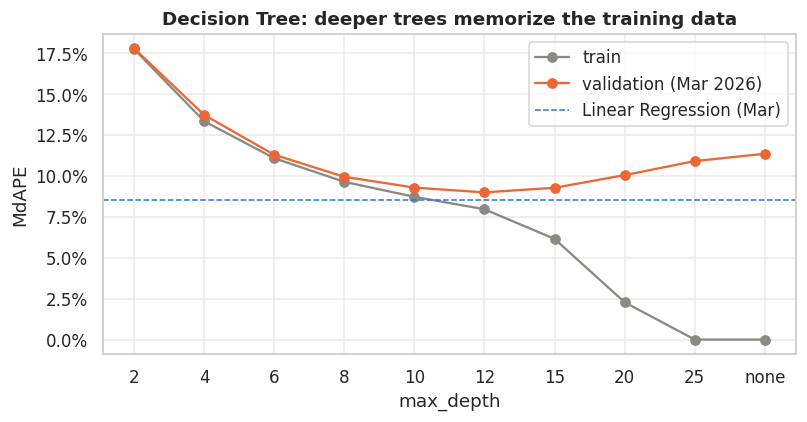

In [4]:
tr_m, va_m = pp.window_split(clean, "2026-03", X_MONTHS)
th_m = pp.fit_thresholds(tr_m)
tr_m, va_m = tr_m[pp.within_thresholds(tr_m, th_m)], va_m[pp.within_thresholds(va_m, th_m)]
depth_rows = []
for d in [2, 4, 6, 8, 10, 12, 15, 20, 25, None]:
    f = mdl.fit(mdl.make_pipeline(dt_make(max_depth=d)), tr_m)
    depth_rows.append({"depth": "none" if d is None else str(d),
                       "train": mdl.full_metrics(tr_m.ClosePrice, mdl.predict_price(f, tr_m))["MdAPE"],
                       "validation": mdl.full_metrics(va_m.ClosePrice, mdl.predict_price(f, va_m))["MdAPE"]})
depth_curve = pd.DataFrame(depth_rows)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(depth_curve.depth, depth_curve.train, marker="o", color=GREY, label="train")
ax.plot(depth_curve.depth, depth_curve.validation, marker="o", color=ORANGE, label="validation (Mar 2026)")
ax.axhline(base_val.query("test_month == '2026-03'").MdAPE.iloc[0], color=BLUE, ls="--", lw=1, label="Linear Regression (Mar)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set(xlabel="max_depth", ylabel="MdAPE",
       title="Decision Tree: deeper trees memorize the training data"); ax.legend()
fig.tight_layout(); save(fig, "dt_depth_overfitting"); plt.show()

## 4. Random Forest: tune on validation months

Grid over `max_features` (share of inputs tried at each split) and `min_samples_leaf`. To keep run time reasonable, tuning uses 60 trees on half-size bootstrap samples; the final model uses more trees on full samples.

In [5]:
rf_make = lambda n_estimators=60, max_samples=0.5, **p: RandomForestRegressor(
    n_estimators=n_estimators, max_samples=max_samples, n_jobs=N_JOBS, random_state=pp.SEED, **p)
rf_grid = [{"max_features": f, "min_samples_leaf": l} for f in [0.33, 0.5] for l in [1, 3, 10]]
rf_tune = tune(rf_make, rf_grid)
RF_BEST = {"max_features": float(rf_tune.iloc[0].max_features), "min_samples_leaf": int(rf_tune.iloc[0].min_samples_leaf)}
print("Best Random Forest settings:", RF_BEST)
fmt_table(rf_tune, {"val_MdAPE": "{:.2f}%", "val_R2": "{:.4f}", "worst_month_MdAPE": "{:.2f}%", "sec": "{:.0f}"})

Best Random Forest settings: {'max_features': 0.33, 'min_samples_leaf': 3}


,max_features,min_samples_leaf,val_MdAPE,val_R2,worst_month_MdAPE,sec
1,0.33,3,7.63%,0.9028,7.71%,66
4,0.50,3,7.74%,0.9025,7.82%,92
3,0.50,1,7.74%,0.9036,7.85%,110
0,0.33,1,7.74%,0.9025,7.88%,77
2,0.33,10,7.82%,0.8959,7.96%,55
5,0.50,10,7.88%,0.8988,7.98%,74


**How many trees?** Validation MdAPE (March cutoff) using the first *k* trees of a 200-tree forest.

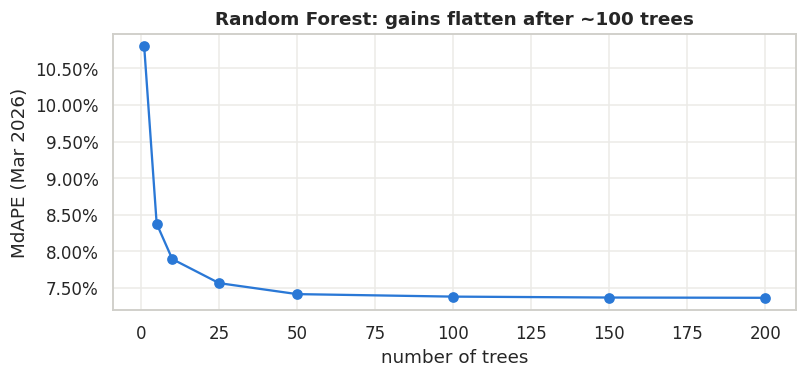

{1: np.float64(10.8), 5: np.float64(8.38), 10: np.float64(7.9), 25: np.float64(7.57), 50: np.float64(7.42), 100: np.float64(7.38), 150: np.float64(7.37), 200: np.float64(7.37)} -> using 150 trees


In [6]:
rf_m = mdl.fit(mdl.make_pipeline(RandomForestRegressor(n_estimators=200, n_jobs=N_JOBS, random_state=pp.SEED, **RF_BEST)), tr_m)
Xv = rf_m.named_steps["prep"].transform(pp.model_frame(va_m))
tree_preds = np.stack([t.predict(Xv) for t in rf_m.named_steps["model"].estimators_])
ks = [1, 5, 10, 25, 50, 100, 150, 200]
curve = [np.median(np.abs(np.exp(tree_preds[:k].mean(0)) - va_m.ClosePrice) / va_m.ClosePrice) * 100 for k in ks]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(ks, curve, marker="o", color=BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set(xlabel="number of trees", ylabel="MdAPE (Mar 2026)",
       title="Random Forest: gains flatten after ~100 trees")
fig.tight_layout(); save(fig, "rf_n_trees"); plt.show()
RF_TREES = 150
print(dict(zip(ks, np.round(curve, 2))), "-> using", RF_TREES, "trees")

## 5. Validation backtest with the chosen settings

In [7]:
final_models = {
    "Decision Tree": DecisionTreeRegressor(random_state=pp.SEED, **DT_BEST),
    "Random Forest": RandomForestRegressor(n_estimators=RF_TREES, n_jobs=N_JOBS, random_state=pp.SEED, **RF_BEST),
}
val_tables = {"Linear Regression": base_val[base_val.role == "validation"]}
for name, m in final_models.items():
    val_tables[name], _ = mdl.rolling_backtest(clean, mdl.make_pipeline(m), VAL_MONTHS, X_MONTHS)
val_mdape = pd.DataFrame({k: v.set_index("test_month").MdAPE for k, v in val_tables.items()})
val_mdape.loc["mean"] = val_mdape.mean()
val_mdape.map(lambda v: f"{v:.2f}%")

,Linear Regression,Decision Tree,Random Forest
test_month,,,
2026-01,8.91%,9.05%,7.58%
2026-02,8.80%,9.18%,7.60%
2026-03,8.52%,9.03%,7.37%
mean,8.75%,9.08%,7.51%


## 6. Score April 2026 (once)

In [8]:
fitted, fit_sec = {}, {}
for name, m in final_models.items():
    t = time.time(); fitted[name] = mdl.fit(mdl.make_pipeline(m), train); fit_sec[name] = time.time() - t
    pred[name] = mdl.predict_price(fitted[name], test)

results = pd.DataFrame([{"model": k, **mdl.full_metrics(y, p), "val_MdAPE": val_mdape.loc["mean", k],
                         "fit_sec": fit_sec.get(k, np.nan)} for k, p in pred.items()]).set_index("model")
assert np.isclose(results.loc["Linear Regression", "MdAPE"], prior.set_index("model").loc["Baseline: Linear Regression", "MdAPE"], atol=0.01)
results["R2_vs_baseline"] = results.R2 - results.loc["Linear Regression", "R2"]
fmt_table(results[["MdAPE", "R2", "R2_vs_baseline", "MAPE", "MAE", "RMSE", "within_10pct", "median_bias_pct", "val_MdAPE", "fit_sec"]],
          {**METRIC_FMT, "R2_vs_baseline": "{:+.4f}"})

,MdAPE,R2,R2_vs_baseline,MAPE,MAE,RMSE,within_10pct,median_bias_pct,val_MdAPE,fit_sec
model,,,,,,,,,,
Linear Regression,8.63%,0.8886,+0.0000,12.02%,"$161,003","$319,549",56.2%,-0.61%,8.75%,
Decision Tree,8.98%,0.8857,-0.0029,12.64%,"$168,812","$323,704",54.0%,-1.68%,9.08%,4
Random Forest,7.58%,0.9060,+0.0174,10.95%,"$148,865","$293,508",60.9%,-1.41%,7.51%,80


## 7. Stability across all four cutoffs

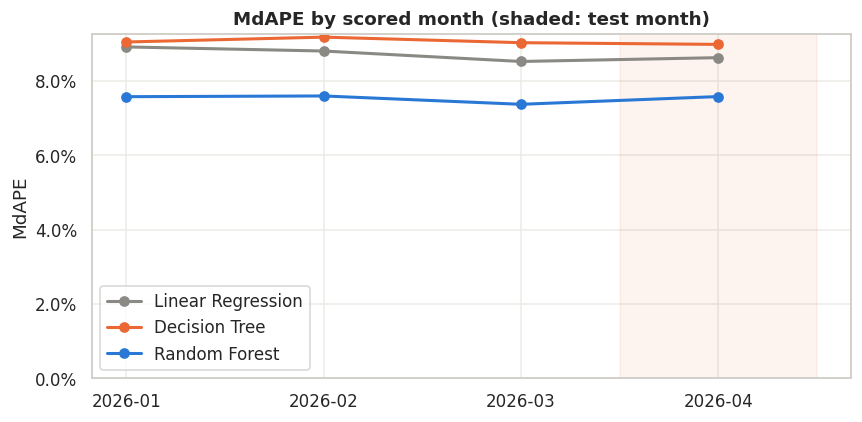

Improvement over Linear Regression (points of MdAPE, negative = better):
            Decision Tree  Random Forest
test_month                              
2026-01              0.13          -1.34
2026-02              0.37          -1.21
2026-03              0.50          -1.15
2026-04              0.36          -1.05


In [9]:
stab = val_mdape.drop("mean").copy()
stab.loc[TEST_MONTH] = results.MdAPE
gap = stab.sub(stab["Linear Regression"], axis=0)

fig, ax = plt.subplots(figsize=(8, 4))
for c in stab.columns:
    ax.plot(stab.index, stab[c], marker="o", lw=2, color=COLORS[c], label=c)
ax.axvspan(2.5, 3.5, color=ORANGE, alpha=0.08)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, None); ax.legend()
ax.set(title="MdAPE by scored month (shaded: test month)", ylabel="MdAPE")
fig.tight_layout(); save(fig, "backtest_stability"); plt.show()
print("Improvement over Linear Regression (points of MdAPE, negative = better):")
print(gap.drop(columns="Linear Regression").round(2).to_string())

## 8. Model behavior: where each model wins and loses

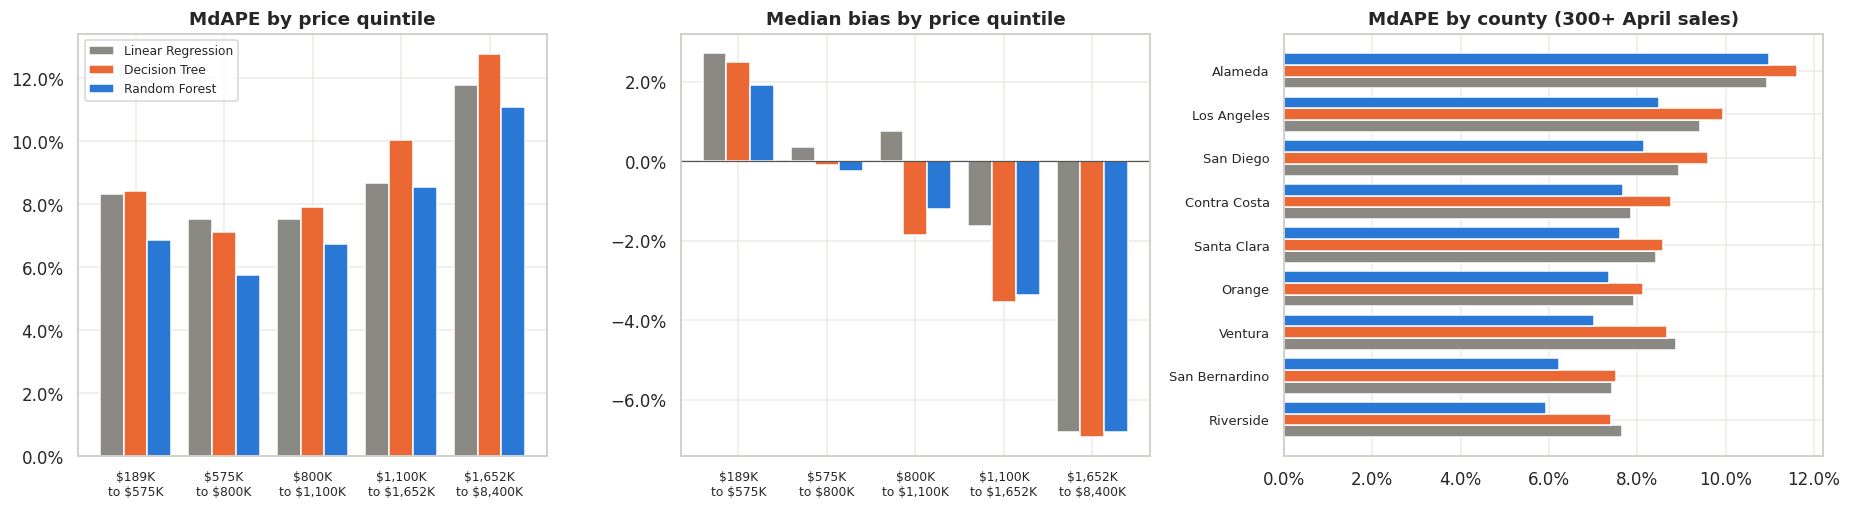

,Linear Regression,Decision Tree,Random Forest
g,,,
Q1: $189K-$575K,8.33%,8.44%,6.88%
Q2: $575K-$800K,7.53%,7.13%,5.77%
"Q3: $800K-$1,100K",7.52%,7.92%,6.75%
"Q4: $1,100K-$1,652K",8.67%,10.03%,8.54%
"Q5: $1,652K-$8,400K",11.78%,12.77%,11.08%


In [10]:
bands = mdl.price_bands(y, 5)
band_tab = pd.concat({k: mdl.error_by_group(y, p, bands)[["MdAPE", "median_bias"]] for k, p in pred.items()}, axis=1)
county = test.CountyOrParish
top = county.value_counts().loc[lambda s: s >= 300].index
cty_tab = pd.concat({k: mdl.error_by_group(y[county.isin(top)], p[county.isin(top)], county[county.isin(top)])["MdAPE"]
                     for k, p in pred.items()}, axis=1).sort_values("Random Forest")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.15]})
x, w = np.arange(len(band_tab)), 0.27
labels = [l.split(": ")[1].replace("-", "\nto ").replace("$", r"\$") for l in band_tab.index]
for i, k in enumerate(pred):
    ax[0].bar(x + (i - 1) * w, band_tab[(k, "MdAPE")], w, color=COLORS[k], label=k)
    ax[1].bar(x + (i - 1) * w, band_tab[(k, "median_bias")], w, color=COLORS[k])
ax[0].set_title("MdAPE by price quintile"); ax[1].set_title("Median bias by price quintile")
ax[1].axhline(0, color="#555", lw=0.8)
for a in ax[:2]: a.set_xticks(x, labels, fontsize=8); a.yaxis.set_major_formatter(mtick.PercentFormatter())
ax[0].legend(fontsize=8)
yy = np.arange(len(cty_tab))
for i, k in enumerate(pred):
    ax[2].barh(yy + (i - 1) * w, cty_tab[k], w, color=COLORS[k])
ax[2].set_yticks(yy, cty_tab.index, fontsize=8.5); ax[2].xaxis.set_major_formatter(mtick.PercentFormatter())
ax[2].set_title("MdAPE by county (300+ April sales)")
fig.tight_layout(); save(fig, "error_by_band_and_county"); plt.show()
fmt_table(band_tab.xs("MdAPE", axis=1, level=1), {k: "{:.2f}%" for k in pred})

**All three models under-predict the most expensive homes.** For trees this is built in: a prediction is an average of training sales in a leaf, so it can never exceed the priciest leaf.

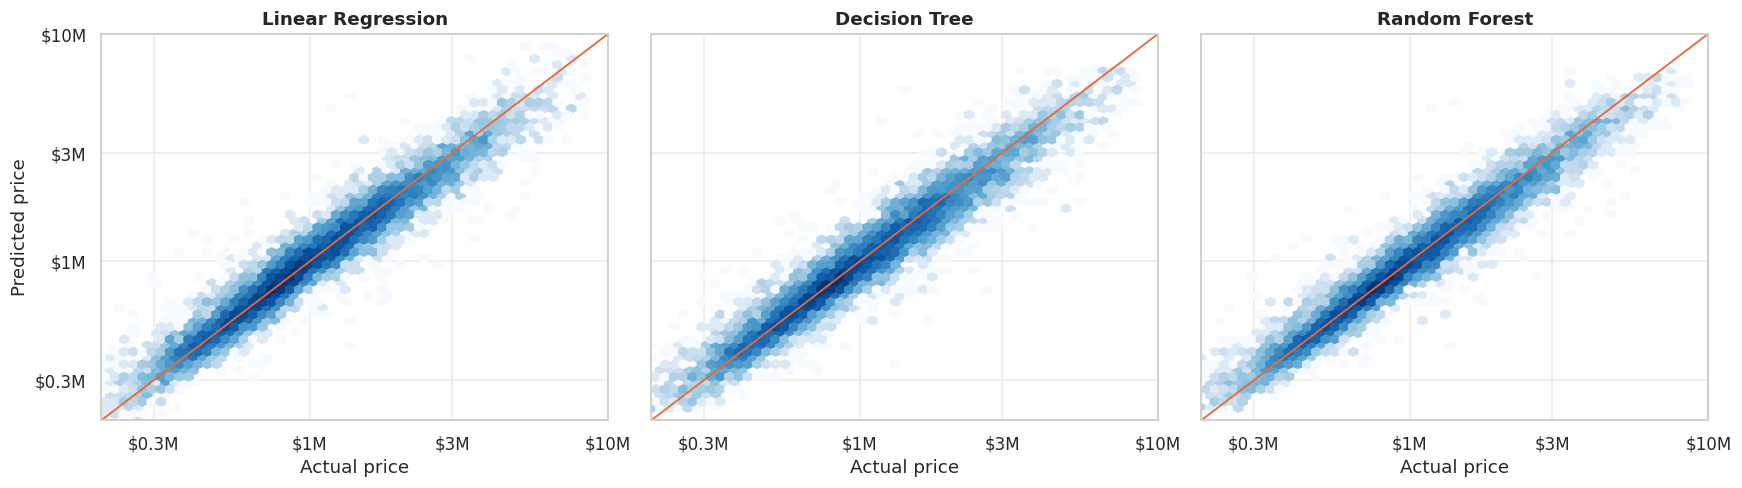

Top 1% of April sales (>= $5,164,491): median prediction / actual
  Linear Regression  0.80
  Decision Tree      0.81
  Random Forest      0.81


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
lim = [2e5, 1e7]
for a, (k, p) in zip(ax, pred.items()):
    a.hexbin(y, p, gridsize=55, xscale="log", yscale="log", mincnt=1, cmap="Blues", bins="log", extent=np.log10(lim * 2))
    a.plot(lim, lim, color=ORANGE, lw=1.2)
    a.set(xlim=lim, ylim=lim, title=k, xlabel="Actual price")
    for axis in (a.xaxis, a.yaxis):
        axis.set_major_locator(mtick.FixedLocator([3e5, 1e6, 3e6, 1e7])); axis.set_minor_locator(mtick.NullLocator())
        axis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e6:g}M"))
ax[0].set_ylabel("Predicted price")
fig.tight_layout(); save(fig, "predicted_vs_actual"); plt.show()
hi = y >= np.quantile(y, 0.99)
print(f"Top 1% of April sales (>= ${np.quantile(y, 0.99):,.0f}): median prediction / actual")
for k, p in pred.items(): print(f"  {k:18s} {np.median(p[hi] / y[hi]):.2f}")

**What the Random Forest relies on** (impurity-based importance; correlated location inputs share credit, so treat as descriptive).

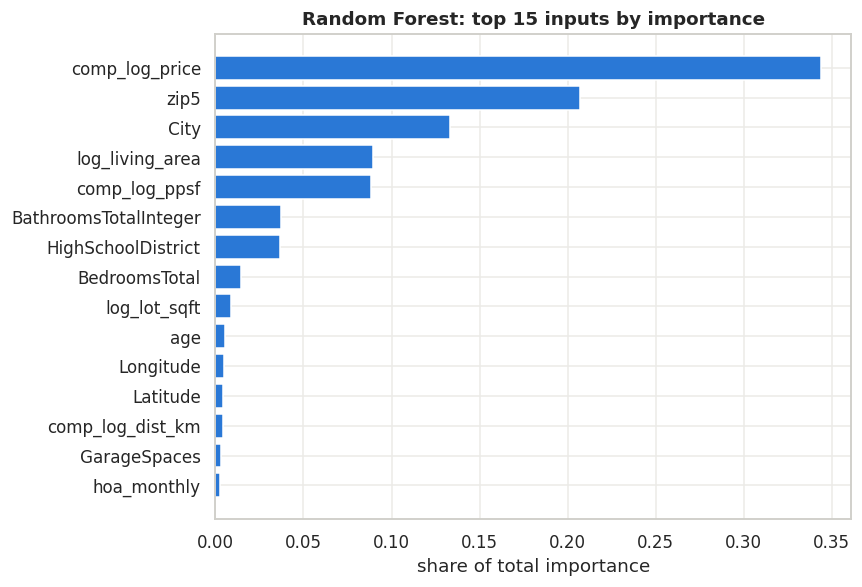

Top 3 share: Random Forest 68% | Decision Tree 99%


In [12]:
rf = fitted["Random Forest"]
names = pd.Series(rf.named_steps["prep"].get_feature_names_out()).str.replace(r"^(num|bin|low|high)__", "", regex=True)
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values().tail(15)
dt_imp = pd.Series(fitted["Decision Tree"].named_steps["model"].feature_importances_, index=names)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(imp.index, imp.values, color=BLUE)
ax.set(title="Random Forest: top 15 inputs by importance", xlabel="share of total importance")
fig.tight_layout(); save(fig, "rf_feature_importance"); plt.show()
print(f"Top 3 share: Random Forest {imp.tail(3).sum():.0%} | Decision Tree {dt_imp.nlargest(3).sum():.0%}")

## 9. Save

In [13]:
# Random Forest file is ~190 MB, so it is not saved; refit it from week5_run_info.json (~1-2 min)
path = MODEL_DIR / "decision_tree.joblib"
joblib.dump(fitted["Decision Tree"], path, compress=3)
print(f"{path.relative_to(ROOT)}  {path.stat().st_size / 1e6:,.1f} MB")

new_rows = results.loc[["Decision Tree", "Random Forest"]].rename(index=lambda k: f"Week 5: {k}").reset_index()
new_rows = new_rows.assign(test_month=TEST_MONTH, train_window_months=X_MONTHS, train_rows=len(train),
                           validation_MdAPE_mean=new_rows.val_MdAPE)[prior.columns]
pd.concat([prior[~prior.model.str.startswith("Week 5")], new_rows], ignore_index=True).to_csv(RES_DIR / "model_results.csv", index=False)

pd.concat({"decision_tree": dt_tune, "random_forest": rf_tune}).to_csv(RES_DIR / "week5_tuning.csv")
stab.to_csv(RES_DIR / "week5_backtest_mdape.csv")
band_tab.to_csv(RES_DIR / "week5_error_by_price_band.csv")
test[["ListingKey", "close_month", "CountyOrParish", "ClosePrice"]].assign(
    **{f"pred_{k.lower().replace(' ', '_')}": p.round(0) for k, p in pred.items()}).to_csv(RES_DIR / "week5_test_predictions.csv", index=False)
(RES_DIR / "week5_run_info.json").write_text(json.dumps({
    "decision_tree": DT_BEST, "random_forest": {**RF_BEST, "n_estimators": RF_TREES}, "seed": pp.SEED,
    "test_month": TEST_MONTH, "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__}}, indent=2))
pd.read_csv(RES_DIR / "model_results.csv")[["model", "MdAPE", "R2", "MAPE", "validation_MdAPE_mean"]].round(4)

models/decision_tree.joblib  0.2 MB


,model,MdAPE,R2,MAPE,validation_MdAPE_mean
0,Reference: comp median price (no model),12.0283,0.7066,17.5404,NaN
1,Reference: comp price/sq ft x living area (no ...,12.7087,0.8606,16.5783,NaN
2,Baseline: Linear Regression,8.6252,0.8886,12.0194,8.7466
3,Week 5: Decision Tree,8.9818,0.8857,12.6446,9.0836
4,Week 5: Random Forest,7.5792,0.9060,10.9543,7.5141


## 10. Summary

In [14]:
r, lr = results, results.loc["Linear Regression"]
print(f"{'model':18s} {'MdAPE':>7s} {'R2':>7s} {'val MdAPE':>10s}")
for k in r.index: print(f"{k:18s} {r.loc[k,'MdAPE']:6.2f}% {r.loc[k,'R2']:.4f} {r.loc[k,'val_MdAPE']:9.2f}%")
best = r.MdAPE.idxmin()
print(f"\nBest: {best} | MdAPE {lr.MdAPE - r.loc[best,'MdAPE']:.2f} points lower, R2 {r.loc[best,'R2'] - lr.R2:+.4f} vs baseline")
print(f"Beats baseline on every cutoff by > 0.4 points: {(gap[best] < -0.4).all()}")

model                MdAPE      R2  val MdAPE
Linear Regression    8.63% 0.8886      8.75%
Decision Tree        8.98% 0.8857      9.08%
Random Forest        7.58% 0.9060      7.51%

Best: Random Forest | MdAPE 1.05 points lower, R2 +0.0174 vs baseline
Beats baseline on every cutoff by > 0.4 points: True


| Model | Strengths | Weaknesses |
|---|---|---|
| Linear Regression | Fast, stable, easy to explain | No interactions (size × location); shrinks toward the average at both price ends |
| Decision Tree | Captures interactions and thresholds; readable | Slightly worse than the baseline on every cutoff (April MdAPE 8.98%, R² 0.886); overfits quickly with depth; step-shaped predictions |
| Random Forest | Best on all four cutoffs, 1.05–1.34 points lower MdAPE than the baseline (April 7.58%, R² 0.906); averaging many trees removes most of the single tree's variance | Slower to train, ~190 MB file; cannot predict above the training price range (top quintile still −6.8% bias); less interpretable |

**Next (Week 6):** add engineered features (bed/bath ratio, school district layer) and re-run these models. Week 7 will try gradient boosting, which Week 3's quick check suggested could do better still.